# Inventory demand forecasting walkthrough

This notebook walks through the same steps as `run_pipeline.py`, with the tables shown along the way. Run `python run_pipeline.py` first so the outputs folder is filled in.

Data: UCI Online Retail, a UK gift wholesaler, Dec 2010 to Dec 2011.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import pandas as pd
from src import prep
pd.set_option("display.width", 140)

## 1. Load and clean

Cancellations get netted out, warehouse adjustments and non product codes get dropped.

In [2]:
raw = prep.load_raw()
df = prep.clean(raw)
print(f"raw rows: {len(raw):,}")
print(f"after cleaning: {len(df):,}")
print(f"cancellation lines kept for netting: {df['is_cancel'].sum():,}")
print(f"distinct products: {df['StockCode'].nunique():,}")

raw rows: 541,909
after cleaning: 536,429
cancellation lines kept for netting: 8,704
distinct products: 3,805


The biggest cancellation in the file. If you only drop the C invoices, this 80k unit order stays in the demand history.

In [3]:
raw[raw.InvoiceNo.str.startswith("C")].nsmallest(3, "Quantity")[["InvoiceNo","StockCode","Description","Quantity","InvoiceDate"]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00


## 2. Weekly demand for the top 50 steady movers

(52, 50)


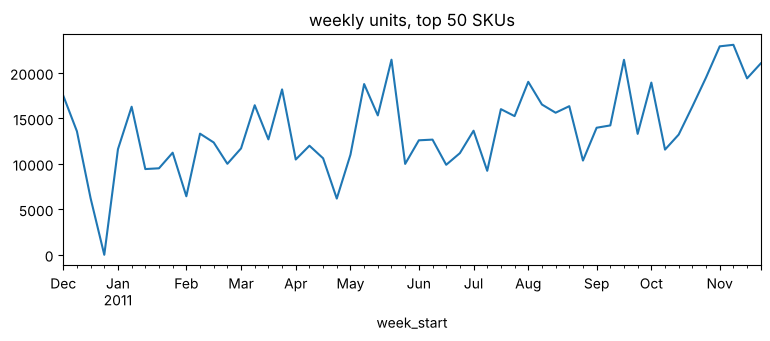

In [4]:
wk = pd.read_csv("data/weekly_demand_top50.csv", index_col=0, parse_dates=True)
print(wk.shape)
wk.sum(axis=1).plot(figsize=(9,3), title="weekly units, top 50 SKUs");

## 3. Forecast accuracy on the 12 test weeks

WAPE averaged across SKUs. `picked` is the model each SKU chose on the validation weeks before.

In [5]:
acc = pd.read_csv("outputs/forecast_accuracy.csv")
t = acc.groupby("method")[["test_wape","test_bias"]].mean().round(3)
t.loc["picked per SKU"] = acc[acc.picked][["test_wape","test_bias"]].mean().round(3)
t.sort_values("test_wape")

,test_wape,test_bias
method,,
ses,0.415,-0.070
ma8,0.424,-0.052
ma4,0.433,-0.052
holt,0.435,-0.027
picked per SKU,0.444,-0.048
naive,0.524,-0.018


Plain SES across the board beat the per SKU pick. With only 12 validation weeks, picking a winner per SKU mostly picks noise. So the forward looking reorder points use SES for everything.

## 4. Policy simulation

Same starting stock, same real demand, 2 week lead time, lost sales.

In [6]:
sim = pd.read_csv("outputs/policy_simulation.csv")
sim.groupby("policy").agg(fill_rate=("fill_rate","mean"),
                          skus_stocked_out=("stockout_weeks", lambda s:(s>0).sum()),
                          units_short=("units_short","sum"),
                          avg_stock_value=("avg_inventory_value","sum")).round(3)

,fill_rate,skus_stocked_out,units_short,avg_stock_value
policy,,,,
flat_rule,0.881,36,35343.462,55090.535
forecast_ss,0.955,21,14008.525,100605.244


## 5. Reorder points for the next cycle

In [7]:
rop = pd.read_csv("outputs/reorder_points.csv")
rop.head(15)

,sku,description,abc,xyz,unit_price,model,weekly_forecast,forecast_rmse,safety_stock,reorder_point,flat_rule_rop,stockout_risk_flat_rule,order_qty_4wk
0,22086,Paper Chain Kit 50'S Christmas,A,Z,2.95,ses,1615.8,446.1,1038,4270,2107,0.963,6464
1,82494L,Wooden Frame Antique White,A,Y,2.95,ses,237.7,66.4,155,630,350,0.909,951
2,22197,Popcorn Holder,A,Z,0.85,ses,2822.8,1224.6,2849,8495,3560,0.886,11292
3,21034,Rex Cash+Carry Jumbo Shopper,B,Y,0.95,ses,78.2,22.9,54,210,119,0.875,313
4,22112,Chocolate Hot Water Bottle,A,Z,4.95,ses,377.5,166.9,389,1144,502,0.858,1511
5,22993,Set Of 4 Pantry Jelly Moulds,A,Y,1.25,ses,391.3,116.9,272,1055,637,0.811,1566
6,22139,Retrospot Tea Set Ceramic 11 Pc,A,Y,4.95,ses,175.4,64.5,150,501,274,0.800,702
7,21977,Pack Of 60 Pink Paisley Cake Cases,A,Y,0.55,ses,464.2,272.1,633,1562,756,0.673,1857
8,22423,Regency Cakestand 3 Tier,A,Y,12.75,ses,231.4,73.9,172,635,417,0.671,926
9,84946,Antique Silver T-Light Glass,A,Y,1.25,ses,578.3,297.8,693,1850,988,0.656,2314


In [8]:
print("SKUs over 50% stockout risk under the flat rule:", (rop.stockout_risk_flat_rule > 0.5).sum(), "of", len(rop))

SKUs over 50% stockout risk under the flat rule: 30 of 50
